Saving titanic.zip to titanic (3).zip
Linear SVM Accuracy: 64.8 %
Non-Linear SVM Accuracy: 63.13 %

Hyperplane: -0.091*x1 + 0.916*x2 + -0.596 = 0
Margins: w1*x1 + w2*x2 + b = +1 or -1


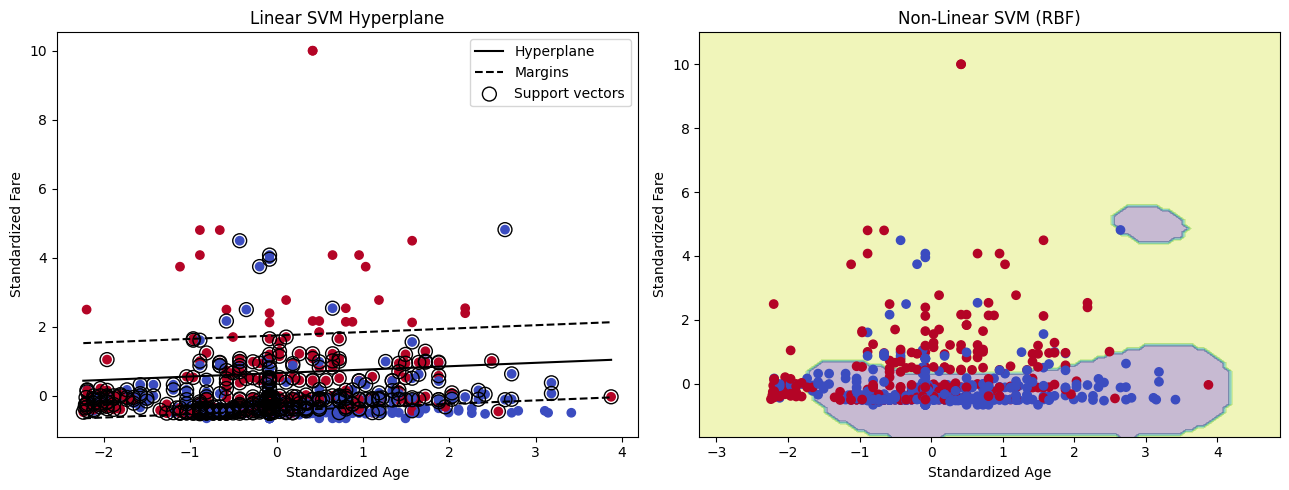

In [8]:
# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile
import io
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score
from sklearn.inspection import DecisionBoundaryDisplay

# 2. Load Titanic dataset
uploaded = files.upload()
file_name = next(iter(uploaded))

# If a ZIP archive is uploaded, extract 'train.csv' explicitly
if file_name.endswith('.zip'):
    with zipfile.ZipFile(io.BytesIO(uploaded[file_name])) as z:
        if 'train.csv' in z.namelist():
            df = pd.read_csv(z.open('train.csv'))
        else:
            # Fallback to the first file in the archive if 'train.csv' is not named exactly that way
            df = pd.read_csv(z.open(z.namelist()[0]))
else:
    df = pd.read_csv(file_name)

X = df[["Age", "Fare"]]
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Preprocess data
prep = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)
X_train = prep.fit_transform(X_train)
X_test = prep.transform(X_test)

# 4. Train Linear and Non-Linear SVM
linear = SVC(kernel="linear").fit(X_train, y_train)
nonlinear = SVC(kernel="rbf").fit(X_train, y_train)

print("Linear SVM Accuracy:",
      round(accuracy_score(y_test, linear.predict(X_test))*100, 2), "%")
print("Non-Linear SVM Accuracy:",
      round(accuracy_score(y_test, nonlinear.predict(X_test))*100, 2), "%")

# 5. Hyperplane formula: w1*x1 + w2*x2 + b = 0
w = linear.coef_[0]
b = linear.intercept_[0]

print(f"\nHyperplane: {w[0]:.3f}*x1 + {w[1]:.3f}*x2 + {b:.3f} = 0")
print(f"Margins: w1*x1 + w2*x2 + b = +1 or -1")

# 6. Visualize both SVM models
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Linear SVM hyperplane and margins
ax = axes[0]
ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm")
xx = np.linspace(X_train[:, 0].min(), X_train[:, 0].max(), 200)

if abs(w[1]) > 1e-10:
    ax.plot(xx, -(w[0]*xx+b)/w[1], "k-", label="Hyperplane")
    ax.plot(xx, -(w[0]*xx+b-1)/w[1], "k--", label="Margins")
    ax.plot(xx, -(w[0]*xx+b+1)/w[1], "k--")

ax.scatter(linear.support_vectors_[:, 0],
           linear.support_vectors_[:, 1],
           s=100, facecolors="none", edgecolors="black",
           label="Support vectors")
ax.set_title("Linear SVM Hyperplane")
ax.set_xlabel("Standardized Age")
ax.set_ylabel("Standardized Fare")
ax.legend()

# Non-Linear SVM decision regions
ax = axes[1]
DecisionBoundaryDisplay.from_estimator(
    nonlinear, X_train, ax=ax, response_method="predict",
    plot_method="contourf", alpha=0.3
)
ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm")
ax.set_title("Non-Linear SVM (RBF)")
ax.set_xlabel("Standardized Age")
ax.set_ylabel("Standardized Fare")

plt.tight_layout()
plt.show()